# Where on the edge is the ant's boundary deficit?

**Question.** Ants spend less time on boundary cells than a walker spread uniformly over the visited
set (census median kappa/kappa_unif 0.81). Does that deficit sit on flat-edge cells (one unvisited
neighbour, u = 1) or on exposed cells (corners, bays, tips: u >= 2)?
Links: `README.md` (registration P0-P4 and results), `NOTEBOOK.md` (lab log),
`notes/open-questions-hypotheses.md`, `notes/kappa-mechanisms-2026-10-15.md`.

## Assumptions and definitions
- rho_u = sum b_u / sum m_u over windows k = 17..26: boundary steps on class-u cells divided by the
  time integral of P_u(t)/A(t). Exactly 1 in expectation for an instantaneously uniform walker,
  with no end-of-window reference (the probe's kappa needs the ~1.11 reference).
- rho_u^ret removes the forced first departure from each newborn cell. Q = rho_1^ret / rho_2+^ret.
- Assumption (from NOTEBOOK, status: untested): exposure is a useful axis. It is confounded with
  cell age, colour and depth, which were not recorded.

## Provenance

In [1]:
import hashlib, json, subprocess, datetime
from pathlib import Path
import numpy as np
import polars as pl

SEED = 20261020
np.random.seed(SEED)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "AGENTS.md").exists())
EXP = ROOT / "experiments/2026-10-20-kappa-exposure-classes"
INPUTS = [EXP / "results/classes.csv", EXP / "results/specs.txt", EXP / "results/rule_stats.csv",
          EXP / "results/analysis.json", EXP / "results/run.log"]
missing = [p for p in INPUTS if not p.exists()]
assert not missing, f"missing inputs: {missing}"
sha = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=ROOT, capture_output=True, text=True).stdout.strip()
print("git", sha, "| seed", SEED)
for p in INPUTS:
    print(hashlib.sha256(p.read_bytes()).hexdigest()[:16], p.relative_to(ROOT))

git 181742c | seed 20261020
50ca657398a6245a experiments/2026-10-20-kappa-exposure-classes/results/classes.csv
b55889c986677019 experiments/2026-10-20-kappa-exposure-classes/results/specs.txt
ead2bf878ffaae46 experiments/2026-10-20-kappa-exposure-classes/results/rule_stats.csv
f0f58d4e194cd2a6 experiments/2026-10-20-kappa-exposure-classes/results/analysis.json
11971a101ccaf86b experiments/2026-10-20-kappa-exposure-classes/results/run.log


## Data and method
`scripts/run.sh` ran `examples/kappa_exposure_classes.rs` (`26 8192 --check`) on 64 stationary census
rules (blank board + 4 patched starts each) and 8 seeds each of the mean-field walker, rotor and
random walk; every window was checked against `probe::probe_walker` and a board scan.
`scripts/analyse.py` scores the registered predictions; `scripts/explore.py` is post hoc.

In [2]:
summary = json.loads((EXP / "results/analysis.json").read_text())
rows = [("P0 reproduction (1152 census windows)", summary["P0_reproduction_held"]),
        ("P1 mean-field calibration", summary["P1_held"]),
        ("P2 deficit survives convention-free ratio", summary["P2_held"]),
        ("P2b kappa/1.105 converts rule by rule", summary["P2b_held"]),
        ("P3 H-exposed (median Q >= 1.18 and Q>1 in >= 75%)", summary["P3_held"]),
        ("P4 Spearman(rho, exposed share) <= -0.4", summary["P4_spearman"] <= -0.4)]
for name, ok in rows:
    print(f"{'HELD  ' if ok else 'FAILED'}  {name}")
print("median Q", round(summary["median_Q"], 3), "CI", [round(x, 3) for x in summary["median_Q_ci95"]],
      "frac Q>1", round(summary["frac_Q_gt_1"], 3), "| P4 rho", round(summary["P4_spearman"], 3))

HELD    P0 reproduction (1152 census windows)
HELD    P1 mean-field calibration
HELD    P2 deficit survives convention-free ratio
HELD    P2b kappa/1.105 converts rule by rule
FAILED  P3 H-exposed (median Q >= 1.18 and Q>1 in >= 75%)
FAILED  P4 Spearman(rho, exposed share) <= -0.4
median Q 1.349 CI [1.091, 1.593] frac Q>1 0.641 | P4 rho 0.197


## Results

In [3]:
rules = pl.read_csv(EXP / "results/rule_stats.csv")
qs = lambda c: np.round(np.percentile(rules[c].to_numpy(), [5, 25, 50, 75, 95]), 3).tolist()
for c in ["rho", "rho1", "rho2p", "rho1_ret", "rho2p_ret", "Q"]:
    print(f"{c:10s} q05/25/50/75/95 {qs(c)}")
print("median between-seed sd: rho %.4f, Q %.4f" % (rules["rho_sd"].median(), rules["Q_sd"].median()))

rho        q05/25/50/75/95 [0.513, 0.719, 0.874, 1.072, 1.453]
rho1       q05/25/50/75/95 [0.26, 0.52, 0.66, 0.778, 1.179]
rho2p      q05/25/50/75/95 [0.686, 1.135, 1.57, 1.914, 16.662]
rho1_ret   q05/25/50/75/95 [0.226, 0.451, 0.591, 0.68, 0.986]
rho2p_ret  q05/25/50/75/95 [0.243, 0.299, 0.411, 0.651, 1.193]
Q          q05/25/50/75/95 [0.575, 0.891, 1.349, 1.873, 2.381]
median between-seed sd: rho 0.0231, Q 0.0108


The ant's convention-free occupation ratio sits below 1 (median 0.87) while flat-edge returns are
at 0.59 and exposed returns at 0.41 of uniform. This does **not** show a mechanism: exposure is
confounded with age, colour and depth.

board-filler runs excluded from the figure (births/step > 0.05 in window 26): ['RLLLRLLL@2', 'RLRRRRLRR@1', 'RLRRRRLRR@3']


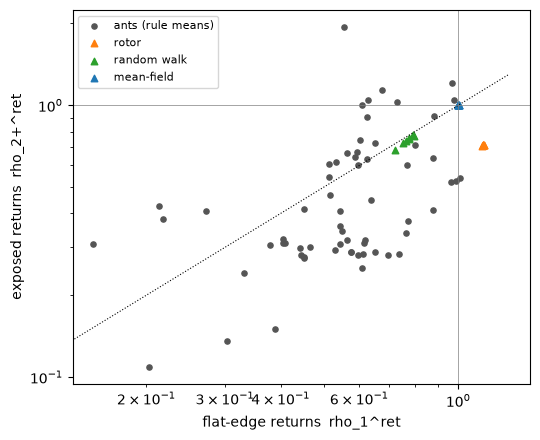

In [4]:
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
df = pl.read_csv(EXP / "results/classes.csv").filter((pl.col("k") >= 17) & (pl.col("k") <= 26))
w26 = df.filter(pl.col("k") == 26).select("spec", (pl.col("new_cells") / pl.col("steps")).alias("birth_rate"))
def per_run(prefix):
    g = df.filter(pl.col("spec").str.starts_with(prefix) if prefix else pl.col("spec").str.contains("@")).group_by("spec").agg(
        [pl.len().alias("n")] + [pl.col(f"{x}{u}").sum().alias(f"{x}{u}") for x in "bfm" for u in range(1, 5)])
    g = g.with_columns(((pl.col("b1") - pl.col("f1")) / pl.col("m1")).alias("r1"),
        ((pl.col("b2") + pl.col("b3") + pl.col("b4") - pl.col("f2") - pl.col("f3") - pl.col("f4")) / (pl.col("m2") + pl.col("m3") + pl.col("m4"))).alias("r2"))
    return g
ants = per_run(None).filter(pl.col("n") == 10).join(w26, on="spec")
print("board-filler runs excluded from the figure (births/step > 0.05 in window 26):",
      ants.filter(pl.col("birth_rate") > 0.05)["spec"].to_list())
ants = ants.filter(pl.col("birth_rate") <= 0.05).with_columns(pl.col("spec").str.split("@").list.first().alias("base"))
am = ants.group_by("base").agg(pl.col("r1").mean(), pl.col("r2").mean())
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(am["r1"], am["r2"], s=14, label="ants (rule means)", color="#555")
for name, pre, col in [("rotor", "rotor:", "C1"), ("random walk", "rw:", "C2"), ("mean-field", "mf:", "C0")]:
    g = per_run(pre)
    ax.scatter(g["r1"], g["r2"], s=22, label=name, color=col, marker="^")
ax.plot([0, 1.3], [0, 1.3], lw=0.8, color="k", ls=":")
ax.axvline(1, lw=0.5, color="grey"); ax.axhline(1, lw=0.5, color="grey")
ax.set_xlabel("flat-edge returns  rho_1^ret"); ax.set_ylabel("exposed returns  rho_2+^ret")
ax.set_xscale("log"); ax.set_yscale("log"); ax.legend(fontsize=8); fig.tight_layout()
fig.savefig(EXP / "results/returns_by_class.png", dpi=110)
plt.show()

Each point is one ant rule (mean over complete patched starts, three board-filler runs excluded post hoc) or one calibration-walker seed; Q is the
horizontal-to-vertical ratio (points below the dotted line have Q > 1). The rotor and random walk
also sit below the line, so Q > 1 is not ant-specific; the ants are distinguished by being far
left (low flat-edge returns). The plot does not show why.

## Caveats and controls
- Positive control: mean-field walker rho_u = 1 in every class (P1 held). Reproduction: blank-board
  windows identical to the committed census (P0). Thread count: byte-identical at 3 vs 8 threads.
- **Failed:** P3 (Q > 1 in only 64% of rules) and P4 (wrong sign). Post hoc readings are labelled.
- One cohort, windows (2^16, 2^26], board 8192; 5/256 patched runs escaped and were excluded.

## What this changes, next steps, open questions
- kappa/1.105 is a good rule-level proxy for the time-averaged occupation ratio (median deviation 3.6%).
- Edge exposure does not locate the deficit; flat-edge returns carry its rule-to-rule variation
  (post hoc, Spearman 0.93). Next (unregistered): age-resolved flat-edge returns on fresh rules.